# Road Follower - Train Model

In this notebook we will train a neural network to take an input image, and output a set of x, y values corresponding to a target.

We will be using PyTorch deep learning framework to train ResNet18 neural network architecture model for road follower application.

In [ ]:
import torch
import torch.optim as optim
import torch.nn.functional as F
import torchvision
import torchvision.datasets as datasets
import torchvision.models as models
import torchvision.transforms as transforms
import glob
import PIL.Image
import os
import numpy as np

### Download and extract data

Before you start, you should upload the ``road_following_<Date&Time>.zip`` file that you created in the ``data_collection.ipynb`` notebook on the robot.

> If you're training on the JetBot you collected data on, you can skip this!

You should then extract this dataset by calling the command below:

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!ls '/content/drive/My Drive'


MessageError: Error: credential propagation was unsuccessful

Google Drive is mounted in /content/drive/My Drive.

Copy the data.zip file under to Colab enviroment and unzip it.

If you uploaded to something_folder_name in Google Drive, replace it with /content/drive/MyDrive/something_folder_name/dataset.zip.


In [ ]:
!cp '/content/data/road_following_dataset_xy_2026-11-06_06-53-44.zip' /content/dataset.zip
%cd /content/
!rm -rf dataset/
!unzip dataset.zip

/content
Archive:  dataset.zip
replace dataset_xy/xy_154_052_ce5ded5a-d99b-11f1-bc29-48b02d2e8c18.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: A
  inflating: dataset_xy/xy_154_052_ce5ded5a-d99b-11f1-bc29-48b02d2e8c18.jpg  
  inflating: dataset_xy/xy_139_026_86e6ec92-d99b-11f1-bc29-48b02d2e8c18.jpg  
  inflating: dataset_xy/xy_105_020_bf8ce3fa-d999-11f1-bc29-48b02d2e8c18.jpg  
  inflating: dataset_xy/xy_031_049_244a9b16-d99a-11f1-bc29-48b02d2e8c18.jpg  
  inflating: dataset_xy/xy_111_027_29ed3fd8-d995-11f1-af98-48b02d2e8c18.jpg  
  inflating: dataset_xy/xy_093_051_9b8ec08a-d9ae-11f1-bbfc-48b02d2e8c18.jpg  
  inflating: dataset_xy/xy_036_095_3ca98c76-d9ae-11f1-bbfc-48b02d2e8c18.jpg  
  inflating: dataset_xy/xy_103_027_5aeba53a-d994-11f1-af98-48b02d2e8c18.jpg  
  inflating: dataset_xy/xy_033_055_0021b81e-d995-11f1-af98-48b02d2e8c18.jpg  
  inflating: dataset_xy/xy_064_055_d0fab106-d99b-11f1-bc29-48b02d2e8c18.jpg  
  inflating: dataset_xy/xy_074_033_a34fd4e8-d99b-11f1-bc29-48b02d2e8c18.jpg  

In [ ]:

!ls

data  dataset_xy  dataset.zip  dumb  sample_data


### Create Dataset Instance

Here we create a custom ``torch.utils.data.Dataset`` implementation, which implements the ``__len__`` and ``__getitem__`` functions.  This class
is responsible for loading images and parsing the x, y values from the image filenames.  Because we implement the ``torch.utils.data.Dataset`` class,
we can use all of the torch data utilities :)

We hard coded some transformations (like color jitter) into our dataset.  We made random horizontal flips optional (in case you want to follow a non-symmetric path, like a road
where we need to 'stay right').  If it doesn't matter whether your robot follows some convention, you could enable flips to augment the dataset.

In [ ]:
def get_x(path, width):
    """Gets the x value from the image filename"""
    return (float(int(path.split("_")[1])) - width/2) / (width/2)

def get_y(path, height):
    """Gets the y value from the image filename"""
    return (float(int(path.split("_")[2])) - height/2) / (height/2)

class XYDataset(torch.utils.data.Dataset):

    def __init__(self, directory, random_hflips=False):
        self.directory = directory
        self.random_hflips = random_hflips
        self.image_paths = glob.glob(os.path.join(self.directory, '*.jpg'))
        self.color_jitter = transforms.ColorJitter(0.3, 0.3, 0.3, 0.3)

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image_path = self.image_paths[idx]

        image = PIL.Image.open(image_path)
        width, height = image.size
        x = float(get_x(os.path.basename(image_path), width))
        y = float(get_y(os.path.basename(image_path), height))

        if float(np.random.rand()) > 0.5:
            image = transforms.functional.hflip(image)
            x = -x

        image = self.color_jitter(image)
        image = transforms.functional.resize(image, (224, 224))
        image = transforms.functional.to_tensor(image)
        image = image.numpy()[::-1].copy()
        image = torch.from_numpy(image)
        image = transforms.functional.normalize(image, [0.485, 0.456, 0.406], [0.229, 0.224, 0.225])

        return image, torch.tensor([x, y]).float()

dataset = XYDataset('dataset_xy', random_hflips=False)

### Split dataset into train and test sets
Once we read dataset, we will split data set in train and test sets. In this example we split train and test a 90%-10%. The test set will be used to verify the accuracy of the model we train.

In [ ]:
test_percent = 0.1
num_test = int(test_percent * len(dataset))
train_dataset, test_dataset = torch.utils.data.random_split(dataset, [len(dataset) - num_test, num_test])

### Create data loaders to load data in batches

We use ``DataLoader`` class to load data in batches, shuffle data and allow using multi-subprocesses. In this example we use batch size of 64. Batch size will be based on memory available with your GPU and it can impact accuracy of the model.

In [ ]:
train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True,
    num_workers=0
)

test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=True,
    num_workers=0
)

### Define Neural Network Model

We use ResNet-18 model available on PyTorch TorchVision.

In a process called transfer learning, we can repurpose a pre-trained model (trained on millions of images) for a new task that has possibly much less data available.


More details on ResNet-18 : https://github.com/pytorch/vision/blob/master/torchvision/models/resnet.py

More Details on Transfer Learning: https://www.youtube.com/watch?v=yofjFQddwHE

In [ ]:
model = models.resnet18(pretrained=True)

ResNet model has fully connect (fc) final layer with 512 as ``in_features`` and we will be training for regression thus ``out_features`` as 1

Finally, we transfer our model for execution on the GPU

In [ ]:
model.fc = torch.nn.Linear(512, 2)
device = torch.device('cuda')
model = model.to(device)

### Train Regression:

We train for 50 epochs and save best model if the loss is reduced.

In [ ]:
NUM_EPOCHS = 20
BEST_MODEL_PATH = 'best_steering_model_xy.pth'
best_loss = 1e9

optimizer = optim.Adam(model.parameters())

for epoch in range(NUM_EPOCHS):

    model.train()
    train_loss = 0.0
    for images, labels in iter(train_loader):
        images = images.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = F.mse_loss(outputs, labels)
        train_loss += float(loss)
        loss.backward()
        optimizer.step()
    train_loss /= len(train_loader)

    model.eval()
    test_loss = 0.0
    for images, labels in iter(test_loader):
        images = images.to(device)
        labels = labels.to(device)
        outputs = model(images)
        loss = F.mse_loss(outputs, labels)
        test_loss += float(loss)
    test_loss /= len(test_loader)

    print('%f, %f' % (train_loss, test_loss))
    if test_loss < best_loss:
        torch.save(model.state_dict(), BEST_MODEL_PATH)
        best_loss = test_loss
print('finished')

0.204206, 0.042052
0.044749, 0.012523
0.027821, 0.011353
0.021738, 0.019666
0.020680, 0.016229
0.018303, 0.018524
0.014922, 0.008497
0.013756, 0.009684
0.014658, 0.008840
0.014780, 0.020443
0.012490, 0.005584
0.011486, 0.010916
0.010514, 0.009728
0.009281, 0.010291
0.013182, 0.007955
0.008494, 0.007793
0.010318, 0.007458
0.007004, 0.006731
0.009089, 0.008261
0.006388, 0.005844
finished


Once the model is trained, it will generate ``best_steering_model_xy.pth`` file which you can use for inferencing in the live demo notebook.

If you trained on a different machine other than JetBot, you'll need to upload this to the JetBot to the ``road_following`` example folder.

0.020936, 0.010345
0.007362, 0.006048
0.008839, 0.010088
0.009686, 0.011962
0.005665, 0.005483
0.005812, 0.005565
0.004795, 0.005626
0.006052, 0.005938
0.006417, 0.005586
0.004942, 0.005483
0.004025, 0.006181
0.003891, 0.006607
0.002766, 0.005371
0.003502, 0.005296
0.002838, 0.005431
0.005197, 0.006784
0.003064, 0.007505
0.003310, 0.007258
0.002658, 0.006698
0.003402, 0.004874
0.002239, 0.006029
0.002432, 0.005403
0.002499, 0.005237
0.001810, 0.005171
0.001948, 0.005567
0.001872, 0.007986
0.001574, 0.006745
0.001895, 0.004767
0.001799, 0.004686
0.001733, 0.004195
0.001428, 0.005616
0.001378, 0.003992
0.001172, 0.004726
0.001507, 0.006530
0.002217, 0.006402
0.004470, 0.007085
0.002987, 0.004311
0.001948, 0.005593
0.002235, 0.004164
0.002042, 0.005202
0.001632, 0.006291
0.001968, 0.005197
0.004258, 0.012715
0.002553, 0.006438
0.002207, 0.006482
0.002164, 0.006556
0.001963, 0.005756
0.001749, 0.005043
0.001582, 0.005409
0.002809, 0.005536
Finished


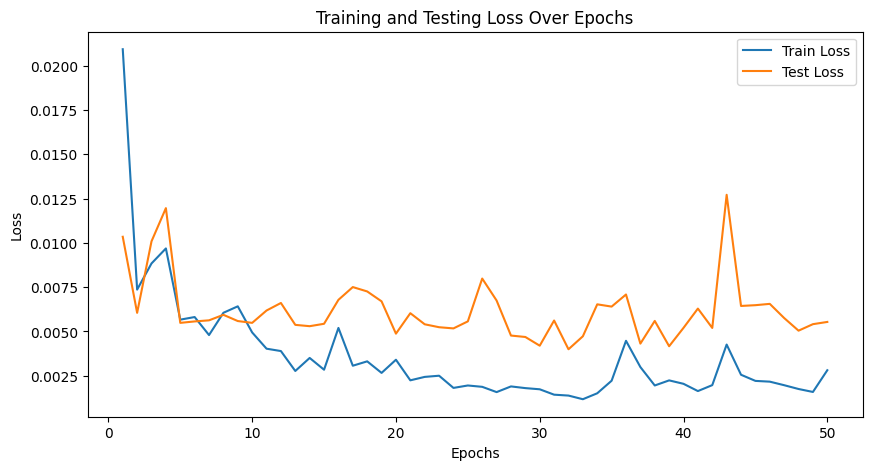

In [ ]:
import matplotlib.pyplot as plt

NUM_EPOCHS = 50
BEST_MODEL_PATH = 'best_steering_model_xy.pth'
best_loss = 1e9

optimizer = optim.Adam(model.parameters())

train_losses = []
test_losses = []

for epoch in range(NUM_EPOCHS):

    model.train()
    train_loss = 0.0
    for images, labels in iter(train_loader):
        images = images.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = F.mse_loss(outputs, labels)
        train_loss += float(loss)
        loss.backward()
        optimizer.step()
    train_loss /= len(train_loader)

    model.eval()
    test_loss = 0.0
    for images, labels in iter(test_loader):
        images = images.to(device)
        labels = labels.to(device)
        outputs = model(images)
        loss = F.mse_loss(outputs, labels)
        test_loss += float(loss)
    test_loss /= len(test_loader)

    train_losses.append(train_loss)
    test_losses.append(test_loss)

    print('%f, %f' % (train_loss, test_loss))
    if test_loss < best_loss:
        torch.save(model.state_dict(), BEST_MODEL_PATH)
        best_loss = test_loss

print('Finished')

# Plotting the losses
plt.figure(figsize=(10, 5))
plt.plot(range(1, NUM_EPOCHS+1), train_losses, label='Train Loss')
plt.plot(range(1, NUM_EPOCHS+1), test_losses, label='Test Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training and Testing Loss Over Epochs')
plt.legend()
plt.show()


To add a graph that shows whether your model is overfitting or underfitting, you can use a library like Matplotlib to plot the training and validation losses at the end of each epoch. This will help you visualize how the losses change during training.

Epoch [1/40], Train Loss: 0.0160, Test Loss: 0.0130
Epoch [2/40], Train Loss: 0.0090, Test Loss: 0.0265
Epoch [3/40], Train Loss: 0.0034, Test Loss: 0.0032
Epoch [4/40], Train Loss: 0.0020, Test Loss: 0.0027
Epoch [5/40], Train Loss: 0.0011, Test Loss: 0.0023
Epoch [6/40], Train Loss: 0.0020, Test Loss: 0.0106
Epoch [7/40], Train Loss: 0.0038, Test Loss: 0.0055
Epoch [8/40], Train Loss: 0.0068, Test Loss: 0.0044
Epoch [9/40], Train Loss: 0.0020, Test Loss: 0.0048
Epoch [10/40], Train Loss: 0.0023, Test Loss: 0.0064
Epoch [11/40], Train Loss: 0.0026, Test Loss: 0.0032
Epoch [12/40], Train Loss: 0.0018, Test Loss: 0.0051
Epoch [13/40], Train Loss: 0.0014, Test Loss: 0.0034
Epoch [14/40], Train Loss: 0.0015, Test Loss: 0.0069
Epoch [15/40], Train Loss: 0.0022, Test Loss: 0.0033
Epoch [16/40], Train Loss: 0.0027, Test Loss: 0.0082
Epoch [17/40], Train Loss: 0.0022, Test Loss: 0.0056
Epoch [18/40], Train Loss: 0.0029, Test Loss: 0.0052
Epoch [19/40], Train Loss: 0.0013, Test Loss: 0.0026
Ep

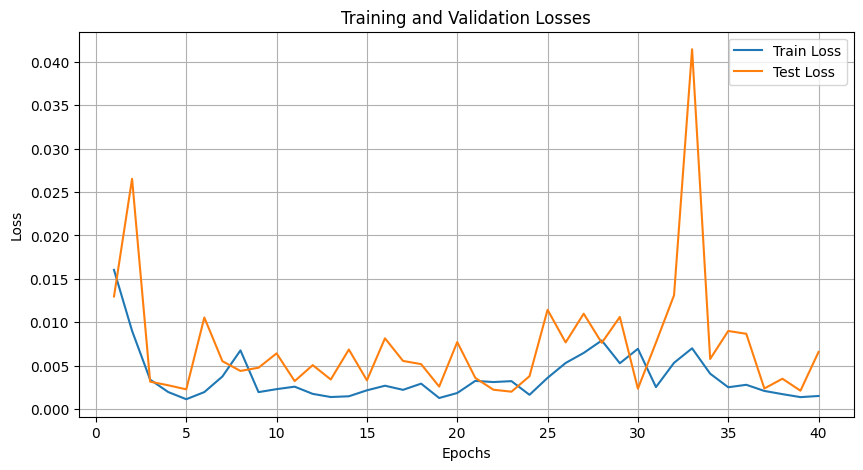

finished


In [ ]:
import matplotlib.pyplot as plt

NUM_EPOCHS = 40
BEST_MODEL_PATH = 'best_steering_model_xy.pth'
best_loss = 1e9

optimizer = optim.Adam(model.parameters())

# Lists to store training and validation losses
train_losses = []
test_losses = []

for epoch in range(NUM_EPOCHS):
    model.train()
    train_loss = 0.0
    for images, labels in iter(train_loader):
        images = images.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = F.mse_loss(outputs, labels)
        train_loss += float(loss)
        loss.backward()
        optimizer.step()
    train_loss /= len(train_loader)

    model.eval()
    test_loss = 0.0
    for images, labels in iter(test_loader):
        images = images.to(device)
        labels = labels.to(device)
        outputs = model(images)
        loss = F.mse_loss(outputs, labels)
        test_loss += float(loss)
    test_loss /= len(test_loader)

    # Append the training and validation losses to the lists
    train_losses.append(train_loss)
    test_losses.append(test_loss)

    print('Epoch [%d/%d], Train Loss: %.4f, Test Loss: %.4f' % (epoch + 1, NUM_EPOCHS, train_loss, test_loss))

    if test_loss < best_loss:
        torch.save(model.state_dict(), BEST_MODEL_PATH)
        best_loss = test_loss

# Plot the training and validation losses
plt.figure(figsize=(10, 5))
plt.plot(range(1, NUM_EPOCHS + 1), train_losses, label='Train Loss')
plt.plot(range(1, NUM_EPOCHS + 1), test_losses, label='Test Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Training and Validation Losses')
plt.grid(True)
plt.show()

print('finished')


In this modified code, we added two lists (train_losses and test_losses) to store the training and validation losses at the end of each epoch. After training is complete, we use Matplotlib to plot these lists to visualize the training and validation loss curves. This graph will help you assess whether your model is overfitting or underfitting during training.